In [ ]:
from pathlib import Path
import pandas as pd
import seaborn as sns

sns.set_theme(style="darkgrid", rc={"axes.facecolor": "#EAEAF2", "grid.color": "white"})


def fitness_display_label(fitness_col):
    return {
        'mean_speed_y': r'$\mathit{AS}$',
        'mean_pop_diversity': r'$\mathit{ASD}$',
    }.get(fitness_col, fitness_col.replace('_', ' '))


def parameter_display_label(parameter):
    return {
        'population_size': 'Population size',
        'offspring_size': 'Offspring size',
        'num_generations': 'Num generations',
        'parent_selection': 'Parent selection',
        'survivor_selection': 'Survivor selection',
    }.get(parameter, parameter.replace('_', ' ').title())


def selection_category_order(values):
    categories = values.dropna().astype(str).unique()
    try:
        return sorted(categories, key=float)
    except ValueError:
        return sorted(categories)


plot_options = [
    {
        'name': 'With number generations',
        'folder': Path('With number generations'),
        'parameters_file': 'parameters.csv',
        'speed_file': 'result_mean_speed_y.csv',
        'measure_file': 'result_measure.csv',
        'param_cols': [
            'population_size', 'offspring_size', 'num_generations',
            'parent_selection', 'survivor_selection',
        ],
        'output_prefix': 'with_generations',
    },
    {
        'name': 'Without number generations',
        'folder': Path('Without number generations'),
        'parameters_file': 'parameters_nieuw.csv',
        'speed_file': 'result_mean_speed_y.csv',
        'measure_file': 'result_measure.csv',
        'param_cols': [
            'population_size', 'offspring_size',
            'parent_selection', 'survivor_selection',
        ],
        'output_prefix': 'without_generations',
    },
]

for option in plot_options:
    folder = option['folder']
    parameters = pd.read_csv(folder / option['parameters_file'])
    speed = pd.read_csv(folder / option['speed_file'])
    measure = pd.read_csv(folder / option['measure_file'])
    option['data'] = parameters.merge(
        speed, on='full_experiment'
    ).merge(measure, on='full_experiment')

    option['plot_param_cols'] = [
        column for column in option['param_cols']
        if option['data'][column].nunique(dropna=True) > 1
    ]
    constant_columns = set(option['param_cols']) - set(option['plot_param_cols'])
    if constant_columns:
        print(
            f"{option['name']}: omitted constant input parameter(s): "
            f"{', '.join(sorted(constant_columns))}"
        )

In [2]:
# Pairwise parameter interaction matrix.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize


deep_blue = '#000080'
blue_cmap = LinearSegmentedColormap.from_list(
    'deep_blue', ['#f4f7fc', '#91add0', deep_blue]
)
blue_cmap.set_under('#f4f7fc')
blue_cmap.set_over('#000050')


def pairwise_plot(data, fitness_col, param_cols, output_path, dataset_name):
    plot_data = data[param_cols + [fitness_col]].dropna().copy()
    for column in {'parent_selection', 'survivor_selection'} & set(param_cols):
        plot_data[column] = pd.to_numeric(plot_data[column], errors='raise')

    n_params = len(param_cols)
    fitness_values = plot_data[fitness_col]
    color_norm = Normalize(
        vmin=fitness_values.quantile(0.05),
        vmax=fitness_values.quantile(0.95),
    )
    fig, axes = plt.subplots(
        n_params, n_params,
        figsize=(4.2 * n_params, 4.2 * n_params),
        constrained_layout=True,
    )

    for i, col_i in enumerate(param_cols):
        for j, col_j in enumerate(param_cols):
            ax = axes[i, j]
            if i == j:
                sns.scatterplot(
                    x=col_i, y=fitness_col, data=plot_data, ax=ax,
                    s=18, alpha=0.22, color='#6f8fb7', edgecolor='none',
                )
                sns.regplot(
                    x=col_i, y=fitness_col, data=plot_data, ax=ax,
                    lowess=True, scatter=False, ci=None,
                    color=deep_blue, line_kws={'linewidth': 2.4, 'zorder': 3},
                )
            else:
                hb = ax.hexbin(
                    plot_data[col_j], plot_data[col_i], C=plot_data[fitness_col],
                    gridsize=14, reduce_C_function=np.mean, mincnt=1,
                    cmap=blue_cmap, norm=color_norm,
                )

            if i == n_params - 1:
                ax.set_xlabel(parameter_display_label(col_j))
            else:
                ax.set_xlabel('')
                ax.tick_params(labelbottom=False)
            if j == 0:
                ax.set_ylabel(parameter_display_label(col_i))
            else:
                ax.set_ylabel('')
                ax.tick_params(labelleft=False)
            ax.grid(alpha=0.15, linewidth=0.6)

    for i, col_i in enumerate(param_cols):
        for j, col_j in enumerate(param_cols):
            if i != j:
                corr = plot_data[[col_i, col_j, fitness_col]].corr().iloc[0, 1]
                ax = axes[i, j]
                ax.text(
                    0.5, 0.9, f'ρ={corr:.2f}',
                    transform=ax.transAxes, ha='center', va='center',
                    fontsize=10, color='black'
                )

    fig.suptitle(
        f'{dataset_name}: pairwise parameter effects on '
        f'{fitness_display_label(fitness_col)}',
        fontsize=16,
    )
    fig.colorbar(
        hb, ax=axes.ravel().tolist(),
        label=f'{fitness_display_label(fitness_col)} (5th-95th percentile scale)',
        shrink=0.82, pad=0.02, extend='both',
    )
    fig.savefig(f'{output_path}_{fitness_col}.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'{output_path}_{fitness_col}.pdf', bbox_inches='tight')
    plt.close(fig)

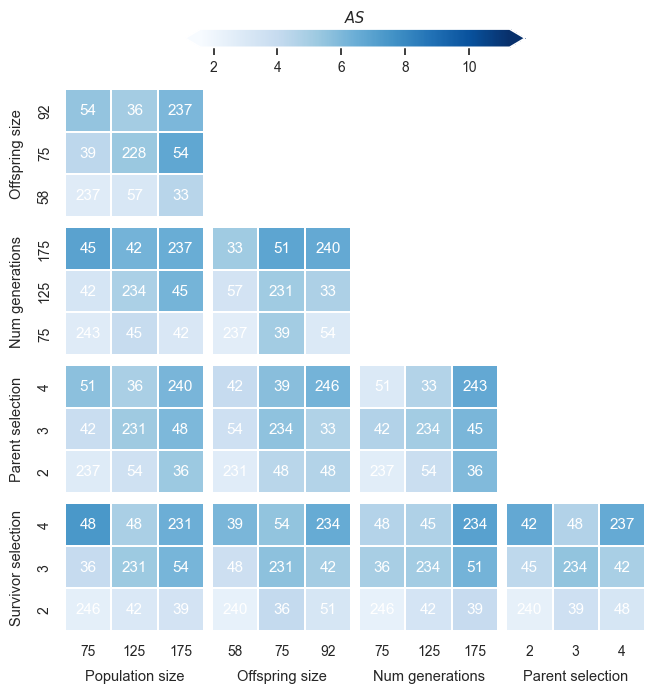

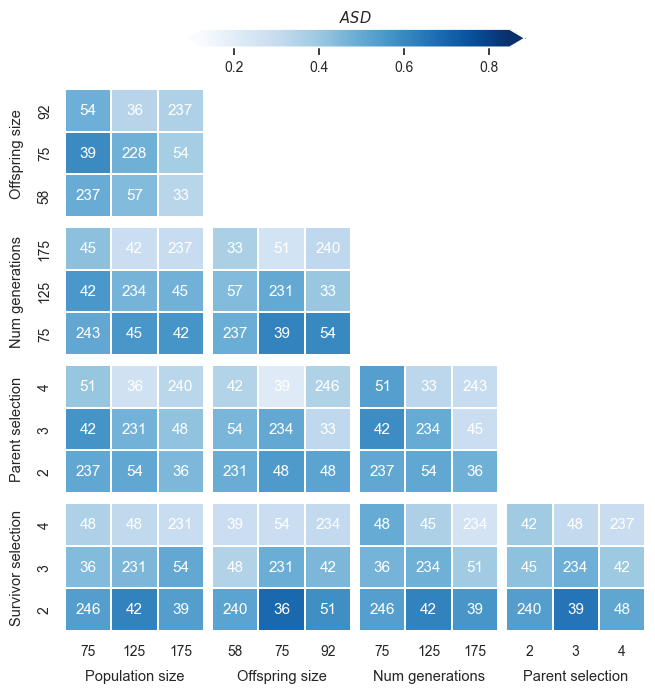

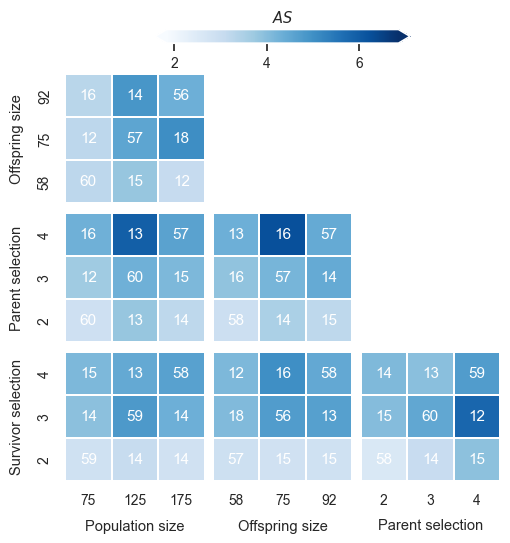

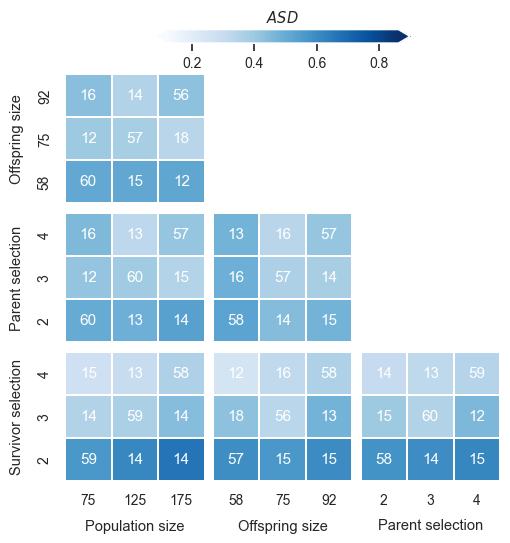

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


def _parameter_bins(values, column):
    if column in {'parent_selection', 'survivor_selection'}:
        labels = selection_category_order(values)
        binned = pd.Categorical(values.astype(str), categories=labels, ordered=True)
        tick_labels = labels
    elif not pd.api.types.is_numeric_dtype(values):
        labels = sorted(values.astype(str).unique())
        binned = pd.Categorical(values.astype(str), categories=labels, ordered=True)
        tick_labels = labels
    else:
        bin_count = min(3, values.nunique())
        intervals = pd.cut(values, bins=bin_count, include_lowest=True, duplicates='drop')
        categories = intervals.cat.categories
        labels = [str(interval) for interval in categories]
        label_map = dict(zip(labels, labels))
        binned = pd.Categorical(
            [label_map[str(interval)] for interval in intervals],
            categories=labels,
            ordered=True,
        )
        tick_labels = [f'{(interval.left + interval.right) / 2:.0f}' for interval in categories]
    return binned, labels, tick_labels


def pairwise_landscape_plot(data, fitness_col, param_cols, output_path, dataset_name):
    plot_data = data[param_cols + [fitness_col]].dropna().copy()
    fitness_values = plot_data[fitness_col]
    vmin, vmax = fitness_values.quantile([0.05, 0.95])
    if vmin == vmax:
        vmin, vmax = fitness_values.min(), fitness_values.max() + 1e-12
    color_norm = Normalize(vmin=vmin, vmax=vmax)
    color_map = plt.get_cmap('Blues')

    n_params = len(param_cols)
    if n_params < 2:
        raise ValueError('At least two varying parameters are required for a pairwise landscape plot.')

    matrix_size = n_params - 1
    figure_width = 2.5 * matrix_size
    fig, axes = plt.subplots(
        matrix_size, matrix_size,
        figsize=(figure_width, (5 / 6) * figure_width),
        squeeze=False,
    )
    fig.subplots_adjust(
        left=0.20, right=0.78, bottom=0.22, top=0.87,
        wspace=0.06, hspace=0.08,
    )

    for row in range(matrix_size):
        y_column = param_cols[row + 1]
        for column in range(matrix_size):
            ax = axes[row, column]
            if column > row:
                ax.set_axis_off()
                continue

            x_column = param_cols[column]
            x_bins, x_labels, x_ticks = _parameter_bins(plot_data[x_column], x_column)
            y_bins, y_labels, y_ticks = _parameter_bins(plot_data[y_column], y_column)
            y_labels = y_labels[::-1]
            y_ticks = y_ticks[::-1]
            grouped = pd.DataFrame({
                'x_bin': x_bins,
                'y_bin': y_bins,
                'fitness': plot_data[fitness_col].to_numpy(),
            }).groupby(['y_bin', 'x_bin'], observed=True)['fitness'].agg(['mean', 'count'])
            means = grouped['mean'].unstack().reindex(index=y_labels, columns=x_labels)
            counts = grouped['count'].unstack().reindex(index=y_labels, columns=x_labels).fillna(0).astype(int)
            mask = counts == 0
            annotations = counts.astype(str)
            ax.set_facecolor('#f2f2f2')
            sns.heatmap(
                means, mask=mask, annot=annotations, fmt='', cmap='Blues',
                vmin=vmin, vmax=vmax, cbar=False, ax=ax,
                xticklabels=x_ticks, yticklabels=y_ticks,
                annot_kws={'fontsize': 11, 'color': 'white'},
                linewidths=0.2, linecolor='white',
            )
            ax.set_xlabel(
                parameter_display_label(x_column) if row == matrix_size - 1 else '',
                fontsize=10.5, rotation=0, ha='center', labelpad=8,
            )
            ax.set_ylabel(
                parameter_display_label(y_column) if column == 0 else '',
                fontsize=10.5, rotation=90, labelpad=10,
            )
            if row != matrix_size - 1:
                ax.tick_params(axis='x', bottom=False, labelbottom=False)
            if column != 0:
                ax.tick_params(axis='y', left=False, labelleft=False)
            ax.tick_params(axis='x', labelsize=10)
            ax.tick_params(axis='y', labelsize=10)

    colorbar_axis = fig.add_axes([0.32, 0.92, 0.34, 0.022])
    colorbar = fig.colorbar(
        ScalarMappable(norm=color_norm, cmap=color_map),
        cax=colorbar_axis, orientation='horizontal', extend='both',
    )
    colorbar.ax.tick_params(labelsize=10)
    colorbar.set_label(fitness_display_label(fitness_col), fontsize=10.5, labelpad=5)
    colorbar.ax.xaxis.set_label_position('top')
    fig.savefig(
        f'{output_path}_{fitness_col}_landscape.png',
        dpi=300, bbox_inches='tight', pad_inches=0.02,
    )
    fig.savefig(
        f'{output_path}_{fitness_col}_landscape.pdf',
        bbox_inches='tight', pad_inches=0.02,
    )
    plt.show()


landscape_fitness_cols = ['mean_speed_y', 'mean_pop_diversity']
for option in plot_options:
    for fitness_col in landscape_fitness_cols:
        pairwise_landscape_plot(
            option['data'], fitness_col, option['plot_param_cols'],
            option['folder'] / option['output_prefix'], option['name'],
        )

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection


def parallel_coordinates_plot(data, fitness_col, param_cols, dataset_name, output_path):
    plot_data = data[param_cols + [fitness_col]].dropna().copy()
    if plot_data.empty:
        raise ValueError(f"No complete rows available for {fitness_col}.")

    coordinates = np.zeros((len(plot_data), len(param_cols)))
    axis_labels = []

    for index, column in enumerate(param_cols):
        values = plot_data[column]
        if column in {'parent_selection', 'survivor_selection'} or not pd.api.types.is_numeric_dtype(values):
            categories = selection_category_order(values)
            positions = np.linspace(0, 1, len(categories)) if len(categories) > 1 else [0.5]
            category_positions = dict(zip(categories, positions))
            coordinates[:, index] = [category_positions[value] for value in values.astype(str)]
            axis_labels.append((column, categories, positions, True))
        else:
            minimum = values.min()
            maximum = values.max()
            if minimum == maximum:
                coordinates[:, index] = 0.5
            else:
                coordinates[:, index] = (values - minimum) / (maximum - minimum)
            axis_labels.append((column, [minimum, maximum], [0, 1], False))

    fitness = plot_data[fitness_col].to_numpy()
    low_threshold, high_threshold = np.quantile(fitness, [0.10, 0.90])
    best_settings = plot_data.loc[fitness >= high_threshold, param_cols + [fitness_col]]
    metric_label = {'mean_speed_y': 'AS', 'mean_pop_diversity': 'ASD'}.get(fitness_col, fitness_col)
    print(f"\nTop 10% parameter settings for {metric_label} ({dataset_name}):")
    print(best_settings.sort_values(fitness_col, ascending=False)[param_cols + [fitness_col]].to_csv(index=False, header=False))

    x_positions = np.arange(len(param_cols))
    segments = [list(zip(x_positions, row)) for row in coordinates]
    groups = [
        ('Worst 10%', fitness <= low_threshold, '#D55E00'),
        ('Best 10%', fitness >= high_threshold, '#0072B2'),
    ]

    reference_data = plot_options[0]['data']
    reference_columns = [column for column in param_cols if column in reference_data.columns]
    reference_plot_data = reference_data[reference_columns + [fitness_col]].dropna()
    reference_fitness = reference_plot_data[fitness_col].to_numpy()
    reference_low, reference_high = np.quantile(reference_fitness, [0.10, 0.90])

    figure_width = max(6.2, 1.4 * len(param_cols))
    fig, axes = plt.subplots(2, 1, figsize=(figure_width, 6.8), sharex=True)
    fig.patch.set_facecolor('white')

    for ax, (group_name, group_mask, color) in zip(axes, groups):
        group_segments = [segment for segment, selected in zip(segments, group_mask) if selected]
        line_alpha = 0.5
        if dataset_name != plot_options[0]['name']:
            if group_name == 'Worst 10%':
                reference_count = np.count_nonzero(reference_fitness <= reference_low)
            else:
                reference_count = np.count_nonzero(reference_fitness >= reference_high)
            overlap_ratio = reference_count / max(int(group_mask.sum()), 1)
            line_alpha = 1 - (1 - line_alpha) ** overlap_ratio

        ax.set_facecolor('#EAEAF2')
        highlighted = LineCollection(
            group_segments, colors=color, linewidths=1.2, alpha=line_alpha
        )
        ax.add_collection(highlighted)

        for index, (column, labels, positions, is_categorical) in enumerate(axis_labels):
            ax.vlines(index, 0, 1, color='#C9CDD3', linewidth=0.8, zorder=0)
            if is_categorical:
                for label, position in zip(labels, positions):
                    ax.text(
                        index + 0.035, position, label,
                        ha='left', va='center', fontsize=13,
                        bbox={'facecolor': '#EAEAF2', 'edgecolor': 'none', 'alpha': 0.85, 'pad': 1},
                    )
            else:
                ax.text(index, 1.02, f'{labels[1]:g}', ha='center', va='bottom', fontsize=13)
                ax.text(index, -0.02, f'{labels[0]:g}', ha='center', va='top', fontsize=13)

        ax.set_xlim(-0.12, len(param_cols) - 0.65)
        ax.set_ylim(-0.08, 1.08)
        ax.set_yticks([])
        ax.grid(axis='x', color='white', alpha=0.9)
        for spine in ax.spines.values():
            spine.set_visible(False)

    axes[-1].set_xticks(
        x_positions,
        [parameter_display_label(column) for column in param_cols],
        rotation=0, ha='center',
    )
    axes[-1].tick_params(axis='x', labelsize=13, pad=5)
    axes[0].tick_params(axis='x', labelbottom=False)
    fig.subplots_adjust(left=0.04, right=0.99, bottom=0.14, top=0.97, hspace=0.32)

    dataset_slug = dataset_name.lower().replace(' ', '_')
    pdf_path = output_path.parent / (
        f'{dataset_slug}_{fitness_col}_best_worst_parallel_coordinates.pdf'
    )
    fig.savefig(pdf_path, bbox_inches='tight', pad_inches=0.02)
    plt.show()


Top 10% parameter settings for AS (With number generations):
199,100,199,4,4,24.434005487807028
199,100,199,4,4,24.434005487807028
199,100,199,4,4,24.434005487807028
150,83,149,3,3,22.04495840612712
150,83,149,3,3,22.04495840612712
150,83,149,3,3,22.04495840612712
174,70,174,4,4,21.768478031455707
174,70,174,4,4,21.768478031455707
174,70,174,4,4,21.768478031455707
62,54,62,2,4,21.16438815950067
62,54,62,2,4,21.16438815950067
62,54,62,2,4,21.16438815950067
124,75,96,3,3,19.539815382292687
124,75,96,3,3,19.539815382292687
124,75,96,3,3,19.539815382292687
175,92,198,4,4,19.42164048529396
175,92,198,4,4,19.42164048529396
175,92,198,4,4,19.42164048529396
133,78,170,3,3,18.883881904574118
133,78,170,3,3,18.883881904574118
133,78,170,3,3,18.883881904574118
174,92,174,2,4,18.877194880755024
174,92,174,2,4,18.877194880755024
174,92,174,2,4,18.877194880755024
187,82,144,3,3,16.708816561151785
187,82,144,3,3,16.708816561151785
187,82,144,3,3,16.708816561151785
56,100,200,4,4,15.115937856472234
5

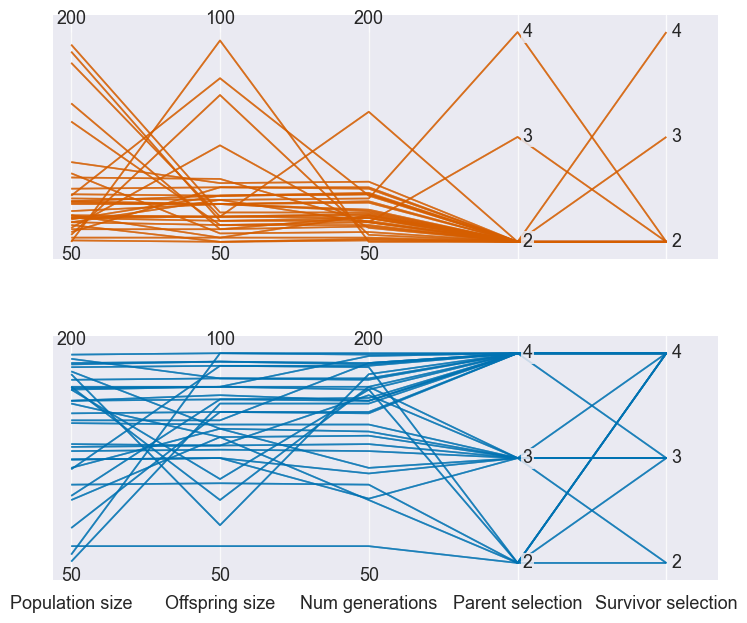


Top 10% parameter settings for ASD (With number generations):
130,77,130,3,2,1.5462692940855398
130,77,130,3,2,1.5462692940855398
130,77,130,3,2,1.5462692940855398
95,80,95,2,2,1.4655454088736737
95,80,95,2,2,1.4655454088736737
95,80,95,2,2,1.4655454088736737
118,82,118,3,3,1.431322700680121
118,82,118,3,3,1.431322700680121
118,82,118,3,3,1.431322700680121
59,53,179,2,2,1.2809348292375848
59,53,179,2,2,1.2809348292375848
59,53,179,2,2,1.2809348292375848
193,98,50,4,4,1.2734935506836302
193,98,50,4,4,1.2734935506836302
193,98,50,4,4,1.2734935506836302
150,83,149,3,3,1.2348155941759562
150,83,149,3,3,1.2348155941759562
150,83,149,3,3,1.2348155941759562
192,98,192,4,3,1.223716327832896
192,98,192,4,3,1.223716327832896
192,98,192,4,3,1.223716327832896
181,67,102,3,3,1.2203383101361054
181,67,102,3,3,1.2203383101361054
181,67,102,3,3,1.2203383101361054
124,75,96,3,3,1.1864869615493454
124,75,96,3,3,1.1864869615493454
124,75,96,3,3,1.1864869615493454
81,84,81,2,2,1.1642881335104558
81,84,81

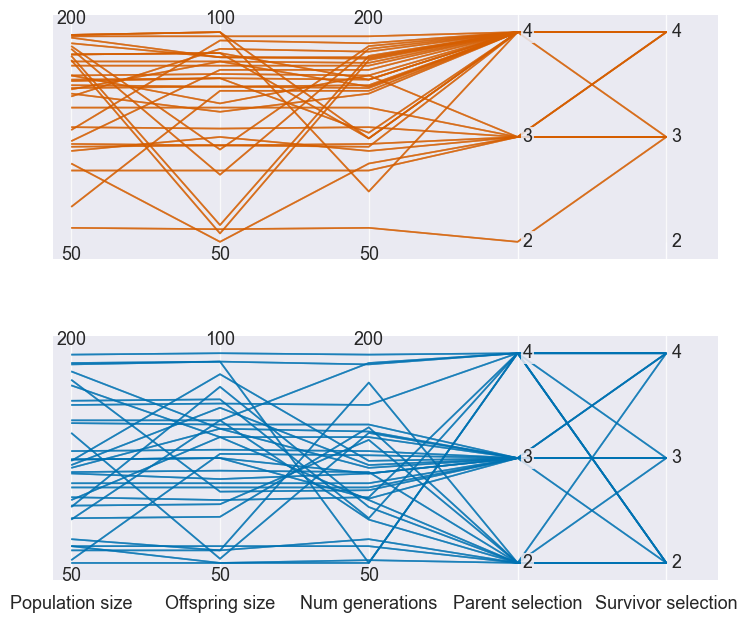


Parameter associations for With number generations:
AS vs ASD (Pearson r): 0.162

AS vs parameters:
  population_size: Pearson r = 0.307
  offspring_size: Pearson r = 0.344
  num_generations: Pearson r = 0.437
  parent_selection: eta = 0.317
  survivor_selection: eta = 0.430

ASD vs parameters:
  population_size: Pearson r = -0.195
  offspring_size: Pearson r = -0.118
  num_generations: Pearson r = -0.288
  parent_selection: eta = 0.284
  survivor_selection: eta = 0.387


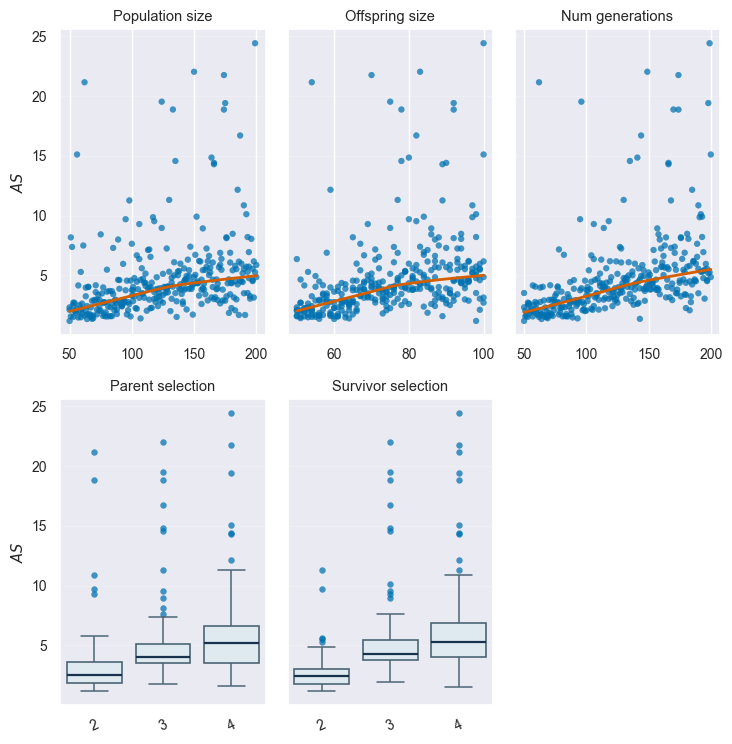

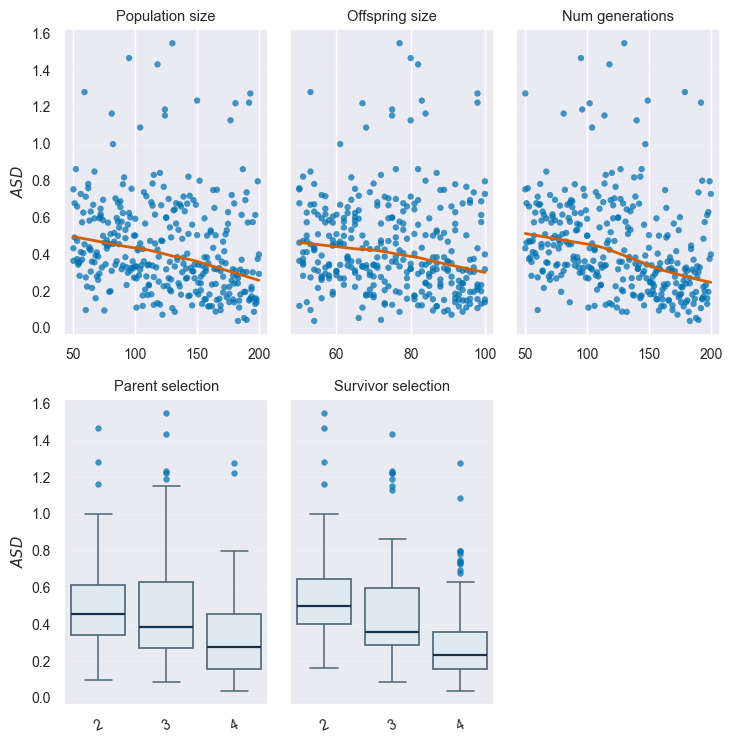


Top 10% parameter settings for AS (Without number generations):
127,76,4,3,17.822580756052854
89,63,4,2,14.85956258875797
157,83,4,4,14.663801972169368
134,87,4,4,10.369913888436797
169,90,4,4,8.748779404869083
111,75,3,3,8.628017874210155
141,81,3,3,8.365983079975525
144,82,3,3,8.307990516537238
141,80,3,3,7.963967240262389
150,83,2,3,7.482063979275987
62,72,3,3,7.285955470891095
153,85,4,4,7.016126500623372
158,86,4,4,6.917808686446179
130,74,3,3,6.842861837535641
105,51,3,3,6.75514100578486
180,56,4,4,6.652479797747075
97,88,4,4,6.313091387393005
192,97,2,4,6.254852725091622
137,69,3,3,6.1158902357978695
170,80,4,4,6.061613197439046
63,62,2,2,6.058715526002271
99,66,2,3,6.030601903012533
194,81,4,4,5.932899787946709
134,79,3,3,5.929658533588665
167,89,4,3,5.906888221144797
173,91,4,4,5.900881291348743



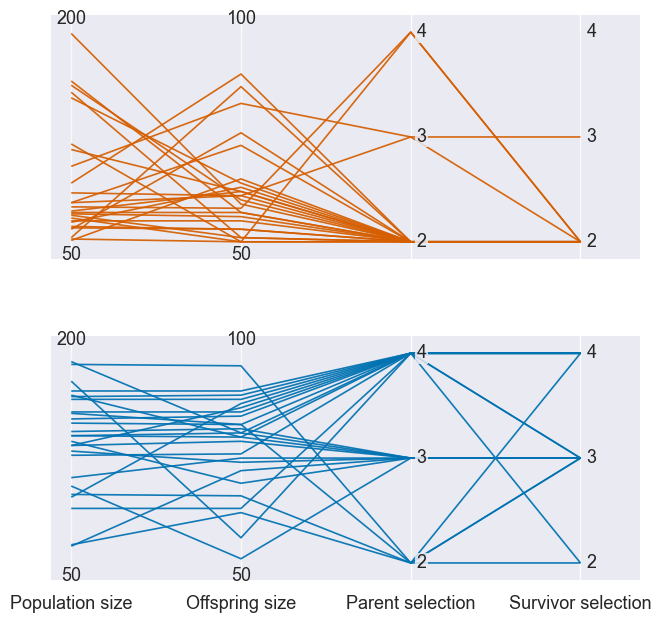


Top 10% parameter settings for ASD (Without number generations):
86,66,2,2,1.7802657928319563
89,63,4,2,1.573996110201995
156,84,4,4,1.555777487295331
63,62,2,2,1.392885580406064
99,66,4,2,0.988154715289853
190,66,2,2,0.9817504318671848
125,62,2,2,0.9799031153769576
51,50,3,2,0.9747272228114036
195,53,2,2,0.9519747348542482
81,87,2,2,0.9459755583254637
181,94,4,2,0.909284248208896
80,60,2,2,0.8876135913992736
107,69,3,2,0.8851350046066264
187,96,4,2,0.8596568145966279
173,91,4,3,0.8463769359815887
145,82,3,2,0.8327013192356931
167,89,4,3,0.8289767018288289
162,60,2,2,0.8103872613474884
120,84,3,3,0.80821936252791
169,55,2,2,0.7960006899555847
62,72,3,3,0.7778542554934923
90,54,2,2,0.7644359905168219
192,98,4,2,0.760380293549371
88,63,2,2,0.7512678590965064
102,67,3,2,0.7148643800371708
132,56,2,2,0.7105262996202527



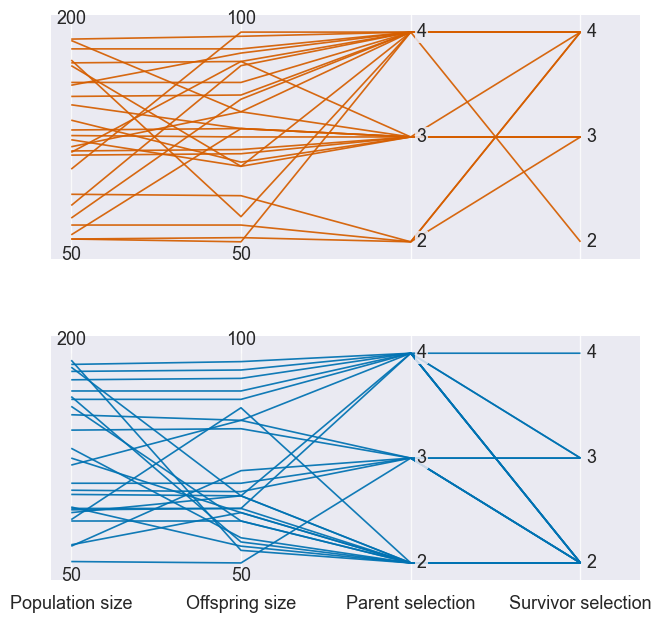


Parameter associations for Without number generations:
AS vs ASD (Pearson r): 0.180

AS vs parameters:
  population_size: Pearson r = 0.232
  offspring_size: Pearson r = 0.212
  parent_selection: eta = 0.355
  survivor_selection: eta = 0.402

ASD vs parameters:
  population_size: Pearson r = -0.065
  offspring_size: Pearson r = -0.111
  parent_selection: eta = 0.205
  survivor_selection: eta = 0.448


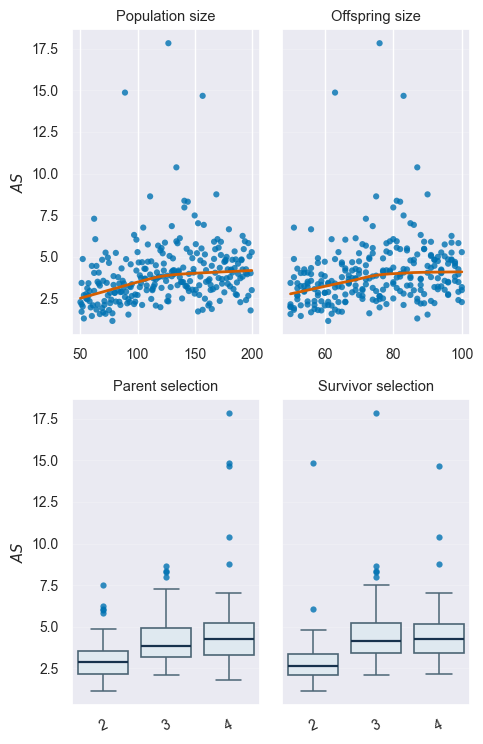

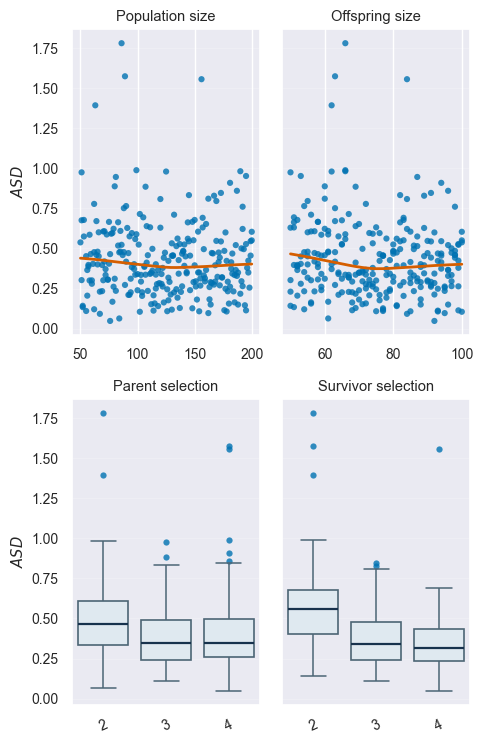

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def effect_plots(data, fitness_cols, param_cols, dataset_name, output_path):
    categorical_params = {'parent_selection', 'survivor_selection'}
    reference_data = plot_options[0]['data']
    reference_dataset_name = plot_options[0]['name']
    reference_alpha = 0.35
    metric_names = {'mean_speed_y': 'AS', 'mean_pop_diversity': 'ASD'}

    print(f'\nParameter associations for {dataset_name}:')
    metric_pair = data[['mean_speed_y', 'mean_pop_diversity']].dropna()
    print(f"AS vs ASD (Pearson r): {metric_pair['mean_speed_y'].corr(metric_pair['mean_pop_diversity']):.3f}")
    for fitness_col in fitness_cols:
        print(f"\n{metric_names.get(fitness_col, fitness_col)} vs parameters:")
        for parameter in param_cols:
            association_data = data[[parameter, fitness_col]].dropna()
            if parameter in categorical_params or not pd.api.types.is_numeric_dtype(association_data[parameter]):
                grouped = association_data.groupby(parameter, observed=True)[fitness_col].agg(['mean', 'size'])
                overall_mean = association_data[fitness_col].mean()
                total_ss = ((association_data[fitness_col] - overall_mean) ** 2).sum()
                between_ss = ((grouped['mean'] - overall_mean) ** 2 * grouped['size']).sum()
                eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan
                print(f'  {parameter}: eta = {eta:.3f}')
            else:
                correlation = association_data[parameter].corr(association_data[fitness_col])
                print(f'  {parameter}: Pearson r = {correlation:.3f}')

    for fitness_col in fitness_cols:
        plot_data = data[param_cols + [fitness_col]].dropna().copy()
        point_alpha = reference_alpha
        if dataset_name != reference_dataset_name:
            reference_plot_data = reference_data[param_cols + [fitness_col]].dropna()
            overlap_ratio = len(reference_plot_data) / max(len(plot_data), 1)
            point_alpha = 1 - (1 - reference_alpha) ** overlap_ratio

        n_columns = 3 if len(param_cols) >= 5 else 2
        n_rows = (len(param_cols) + n_columns - 1) // n_columns
        fig, axes = plt.subplots(
            n_rows, n_columns,
            figsize=(2.5 * n_columns, 3.8 * n_rows), sharey=True, squeeze=False,
        )
        axes = axes.ravel()

        for ax, column in zip(axes, param_cols):
            if column in categorical_params or not pd.api.types.is_numeric_dtype(plot_data[column]):
                plot_data[column] = plot_data[column].astype(str)
                sns.boxplot(
                    data=plot_data, x=column, y=fitness_col, ax=ax,
                    order=selection_category_order(plot_data[column]),
                    color='#dceaf3',
                    boxprops={'edgecolor': '#4c6575', 'linewidth': 1.2, 'zorder': 3},
                    medianprops={'color': '#17324d', 'linewidth': 1.6, 'zorder': 4},
                    whiskerprops={'color': '#4c6575', 'linewidth': 1.1, 'zorder': 3},
                    capprops={'color': '#4c6575', 'linewidth': 1.1, 'zorder': 3},
                    flierprops={
                        'marker': 'o', 'markerfacecolor': '#0072B2',
                        'markeredgecolor': 'none', 'markersize': 4.5, 'alpha': point_alpha,
                    },
                )
                ax.tick_params(axis='x', labelrotation=25)
            else:
                sns.scatterplot(
                    data=plot_data, x=column, y=fitness_col, ax=ax,
                    color='#0072B2', alpha=point_alpha, s=20, edgecolor='none',
                )
                sns.regplot(
                    data=plot_data, x=column, y=fitness_col, ax=ax,
                    lowess=True, scatter=False, ci=None, color='#D55E00',
                    line_kws={'linewidth': 2, 'zorder': 5},
                )

            ax.set_title(parameter_display_label(column), fontsize=10.5)
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.tick_params(axis='both', labelsize=10)
            ax.grid(axis='y', alpha=0.2)

        for ax in axes[len(param_cols):]:
            ax.set_visible(False)
        axis_label = fitness_display_label(fitness_col)
        axes[0].set_ylabel(axis_label, fontsize=10.5)
        if n_rows > 1:
            axes[n_columns].set_ylabel(axis_label, fontsize=10.5)
        fig.tight_layout()
        fig.savefig(
            f'{output_path}_{fitness_col}_effect_plots.pdf',
            bbox_inches='tight', pad_inches=0.02,
        )
        plt.show()


fitness_cols = ['mean_speed_y', 'mean_pop_diversity']

for option in plot_options:
    option_data = option['data']
    option_param_cols = option['plot_param_cols']
    output_path = option['folder'] / option['output_prefix']

    for fitness_col in fitness_cols:
        parallel_coordinates_plot(
            option_data, fitness_col, option_param_cols, option['name'], output_path
        )

    effect_plots(
        option_data, fitness_cols, option_param_cols, option['name'], output_path,
    )